In [ ]:
# ==========================================
# 01. Imports & Environment
# ==========================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydicom
import torch
import torch.nn as nn

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve
)

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.14.1+cu130
Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


In [ ]:
# ==========================================
# 02. Load Test Dataset Metadata
# ==========================================

# Project paths
PROJECT_ROOT = Path.cwd().parents[1]

TEST_CSV = PROJECT_ROOT / "03_Assets" / "Processed" / "test.csv"
MODEL_PATH = PROJECT_ROOT / "04_Exports" / "Models" / "resnet18_lung_opacity.pth"

# Load test metadata
test_df = pd.read_csv(TEST_CSV)

print(f"Test images: {len(test_df):,}")
print("\nClass distribution:")
print(test_df["target"].value_counts().sort_index())

print(f"\nModel checkpoint exists: {MODEL_PATH.exists()}")

Test images: 4,453

Class distribution:
target
0    3387
1    1066
Name: count, dtype: int64

Model checkpoint exists: True


In [3]:
# ==========================================
# 03. Create Test Dataset and DataLoader
# ==========================================

class ChestXrayDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        dicom = pydicom.dcmread(row["path"])
        image = dicom.pixel_array.astype(np.float32)

        # Correct inverted DICOM images
        if dicom.get("PhotometricInterpretation") == "MONOCHROME1":
            image = image.max() - image

        # Normalize pixel intensities to [0, 255]
        image = image - image.min()
        image = image / (image.max() + 1e-8)
        image = (image * 255).astype(np.uint8)

        # Convert to RGB and apply transformations
        image = Image.fromarray(image).convert("RGB")
        image = self.transform(image)

        label = int(row["target"])

        return image, label


# Create dataset
test_dataset = ChestXrayDataset(test_df)

# Create DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# Verify dataset
print(f"Test samples: {len(test_dataset):,}")
print(f"Test batches: {len(test_loader)}")

sample_image, sample_label = test_dataset[0]

print(f"Image shape: {sample_image.shape}")
print(f"Sample label: {sample_label}")

Test samples: 4,453
Test batches: 140
Image shape: torch.Size([3, 224, 224])
Sample label: 0


In [4]:
# ==========================================
# 04. Load Trained ResNet18 Model
# ==========================================

# Recreate model architecture
model = models.resnet18(weights=None)

# Replace final classification layer
model.fc = nn.Linear(model.fc.in_features, 2)

# Load saved checkpoint
checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])

# Move model to GPU and enable evaluation mode
model = model.to(device)
model.eval()

# Display checkpoint information
print(f"Checkpoint epoch: {checkpoint['epoch']}")
print(f"Validation loss: {checkpoint['val_loss']:.4f}")
print(f"Device: {device}")
print("Model loaded successfully!")

Checkpoint epoch: 2
Validation loss: 0.4917
Device: cuda
Model loaded successfully!


In [5]:
# ==========================================
# 05. Generate Test Predictions
# ==========================================

y_true = []
y_pred = []
y_prob = []

model.eval()

with torch.no_grad():
    for batch_idx, (images, labels) in enumerate(test_loader):
        images = images.to(device, non_blocking=True)

        # Generate predictions
        outputs = model(images)

        # Convert outputs to class scores
        probabilities = torch.softmax(outputs, dim=1)[:, 1]
        predictions = outputs.argmax(dim=1)

        # Store results
        y_true.extend(labels.numpy().tolist())
        y_pred.extend(predictions.cpu().numpy().tolist())
        y_prob.extend(probabilities.cpu().numpy().tolist())

        if (batch_idx + 1) % 20 == 0:
            print(f"Processed {batch_idx + 1}/{len(test_loader)} batches")

# Convert to NumPy arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

print("\nTest inference completed!")
print(f"Images evaluated: {len(y_true):,}")
print(f"Predicted No Lung Opacity: {(y_pred == 0).sum():,}")
print(f"Predicted Lung Opacity: {(y_pred == 1).sum():,}")

Processed 20/140 batches
Processed 40/140 batches
Processed 60/140 batches
Processed 80/140 batches
Processed 100/140 batches
Processed 120/140 batches
Processed 140/140 batches

Test inference completed!
Images evaluated: 4,453
Predicted No Lung Opacity: 2,718
Predicted Lung Opacity: 1,735


MODEL PERFORMANCE — TEST SET
Test accuracy: 0.7514 (75.14%)
ROC AUC:       0.8396

Classification Report:
                 precision    recall  f1-score   support

No Lung Opacity     0.9194    0.7378    0.8187      3387
   Lung Opacity     0.4882    0.7946    0.6048      1066

       accuracy                         0.7514      4453
      macro avg     0.7038    0.7662    0.7117      4453
   weighted avg     0.8162    0.7514    0.7675      4453



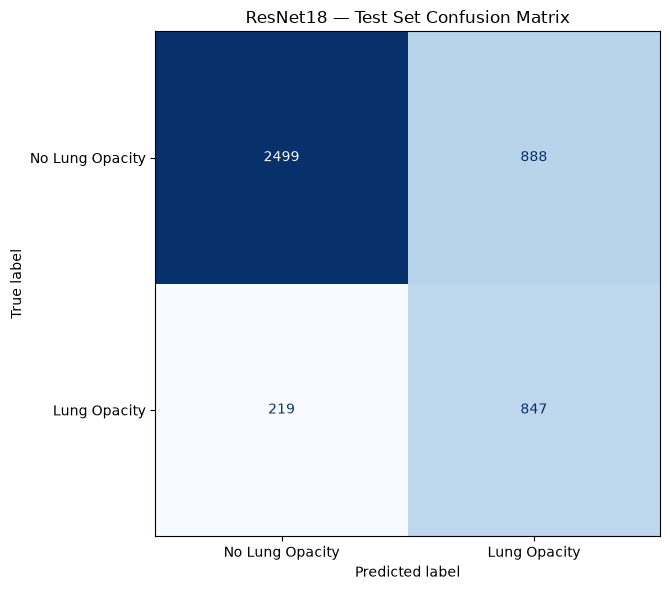

In [6]:
# ==========================================
# 06. Evaluate Model Performance
# ==========================================

from sklearn.metrics import accuracy_score

class_names = ["No Lung Opacity", "Lung Opacity"]

# Calculate performance metrics
accuracy = accuracy_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob)

print("MODEL PERFORMANCE — TEST SET")
print("=" * 45)
print(f"Test accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"ROC AUC:       {auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    digits=4,
    zero_division=0
))

# Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

# Visualize confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

ax.set_title("ResNet18 — Test Set Confusion Matrix")
plt.tight_layout()
plt.show()